In [1]:
#Solar power generation data for PLANT_1 gathered at 15 minutes intervals over a 34 days period.
#There are 2 Datasets for each plant, one dataset is about Solar power generation and other is sensor output installed at each plant.
#Sensor output gives ambient temp, solar panel temp, irradiance all reading taken in 15 minutes interval. One sensor for each plant.

In [2]:
#TASK 
#1. Can we predict the power generation for next couple of days? - this allows for better grid management
#2. Can we identify the need for panel cleaning/maintenance?
#3. Can we identify faulty or suboptimally performing equipment?

In [3]:
#Importing required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import time
import warnings
warnings.filterwarnings('ignore')

In [6]:
df = pd.read_csv('data.csv')

ParserError: Error tokenizing data. C error: Expected 1 fields in line 10, saw 4


In [5]:
#Importing plant 1 Sensor data.
P1_sen = pd.read_csv('/kaggle/input/datasets/anikannal/solar-power-generation-data/Plant_1_Weather_Sensor_Data.csv')
P1_sen

,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0
3,2020-05-15 00:45:00,4135001,HmiyD2TTLFNqkNe,24.846130,22.360852,0.0
4,2020-05-15 01:00:00,4135001,HmiyD2TTLFNqkNe,24.621525,22.165423,0.0
...,...,...,...,...,...,...
3177,2020-06-17 22:45:00,4135001,HmiyD2TTLFNqkNe,22.150570,21.480377,0.0
3178,2020-06-17 23:00:00,4135001,HmiyD2TTLFNqkNe,22.129816,21.389024,0.0
3179,2020-06-17 23:15:00,4135001,HmiyD2TTLFNqkNe,22.008275,20.709211,0.0
3180,2020-06-17 23:30:00,4135001,HmiyD2TTLFNqkNe,21.969495,20.734963,0.0


### Plant 1 Data set data cleaning and EDA

In [6]:
P1_gen.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68778 entries, 0 to 68777
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   DATE_TIME    68778 non-null  object 
 1   PLANT_ID     68778 non-null  int64  
 2   SOURCE_KEY   68778 non-null  object 
 3   DC_POWER     68778 non-null  float64
 4   AC_POWER     68778 non-null  float64
 5   DAILY_YIELD  68778 non-null  float64
 6   TOTAL_YIELD  68778 non-null  float64
dtypes: float64(4), int64(1), object(2)
memory usage: 3.7+ MB


In [7]:
P1_sen.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3182 entries, 0 to 3181
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   DATE_TIME            3182 non-null   object 
 1   PLANT_ID             3182 non-null   int64  
 2   SOURCE_KEY           3182 non-null   object 
 3   AMBIENT_TEMPERATURE  3182 non-null   float64
 4   MODULE_TEMPERATURE   3182 non-null   float64
 5   IRRADIATION          3182 non-null   float64
dtypes: float64(3), int64(1), object(2)
memory usage: 149.3+ KB


In [8]:
P1_gen.columns

Index(['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'DC_POWER', 'AC_POWER',
       'DAILY_YIELD', 'TOTAL_YIELD'],
      dtype='object')

In [9]:
#P1_gen 'DATE_TIME' is > 15-05-2020 00:00     DD-MM-YYYY HH:MM
#P1_sen 'DATE_TIME' is > 2020-05-15 00:00:00  YYYY-MM-DD HH:MM:SS
#So make it uniform
P1_gen['DATE_TIME'] = pd.to_datetime(P1_gen['DATE_TIME'])
P1_sen['DATE_TIME'] = pd.to_datetime(P1_sen['DATE_TIME'])
P1_sen.sample(2)

,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
2356,2020-06-09 09:30:00,4135001,HmiyD2TTLFNqkNe,27.635433,46.078992,0.693144
2019,2020-06-05 21:15:00,4135001,HmiyD2TTLFNqkNe,23.538511,20.658647,0.000000


In [10]:
P1_gen.sample(2)

,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
26770,2020-05-28 15:15:00,4135001,McdE0feGgRqW7Ca,9361.000000,915.612500,7488.000000,7263877.000
45009,2020-06-06 16:30:00,4135001,z9Y9gH1T5YWrNuG,1339.142857,130.314286,6181.857143,7177182.857


In [11]:
#Making one master data set by joining both
master = pd.merge(P1_gen, P1_sen, on ='DATE_TIME', how='left')
master = master.rename(columns={'SOURCE_KEY_x':'SOURCE_KEY_INV','SOURCE_KEY_y':'SOURCE_KEY_SENS','PLANT_ID_x':'PLANT_ID'})
master.drop(['PLANT_ID_y'],axis=1, inplace=True)
master

,DATE_TIME,PLANT_ID,SOURCE_KEY_INV,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,SOURCE_KEY_SENS,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.000,6259559.0,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:00:00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.000,6183645.0,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
2,2020-05-15 00:00:00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.000,6987759.0,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
3,2020-05-15 00:00:00,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.000,7602960.0,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
4,2020-05-15 00:00:00,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.000,7158964.0,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
...,...,...,...,...,...,...,...,...,...,...,...
68773,2020-06-17 23:45:00,4135001,uHbuxQJl8lW7ozc,0.0,0.0,5967.000,7287002.0,HmiyD2TTLFNqkNe,21.909288,20.427972,0.0
68774,2020-06-17 23:45:00,4135001,wCURE6d3bPkepu2,0.0,0.0,5147.625,7028601.0,HmiyD2TTLFNqkNe,21.909288,20.427972,0.0
68775,2020-06-17 23:45:00,4135001,z9Y9gH1T5YWrNuG,0.0,0.0,5819.000,7251204.0,HmiyD2TTLFNqkNe,21.909288,20.427972,0.0
68776,2020-06-17 23:45:00,4135001,zBIq5rxdHJRwDNY,0.0,0.0,5817.000,6583369.0,HmiyD2TTLFNqkNe,21.909288,20.427972,0.0


In [12]:
#Checking null
master.isna().sum()

DATE_TIME              0
PLANT_ID               0
SOURCE_KEY_INV         0
DC_POWER               0
AC_POWER               0
DAILY_YIELD            0
TOTAL_YIELD            0
SOURCE_KEY_SENS        4
AMBIENT_TEMPERATURE    4
MODULE_TEMPERATURE     4
IRRADIATION            4
dtype: int64

In [13]:
#only 4 null in 68778 so drop it
master.dropna(inplace=True)

In [14]:
master.isna().sum()

DATE_TIME              0
PLANT_ID               0
SOURCE_KEY_INV         0
DC_POWER               0
AC_POWER               0
DAILY_YIELD            0
TOTAL_YIELD            0
SOURCE_KEY_SENS        0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
dtype: int64

In [15]:
# lets see which inverter has generated maximum power

In [16]:
max_yield = master.groupby(['SOURCE_KEY_INV']). agg({
    'TOTAL_YIELD' : 'sum',
    'DAILY_YIELD' : 'sum'
}).reset_index().sort_values(by='TOTAL_YIELD', ascending=False)

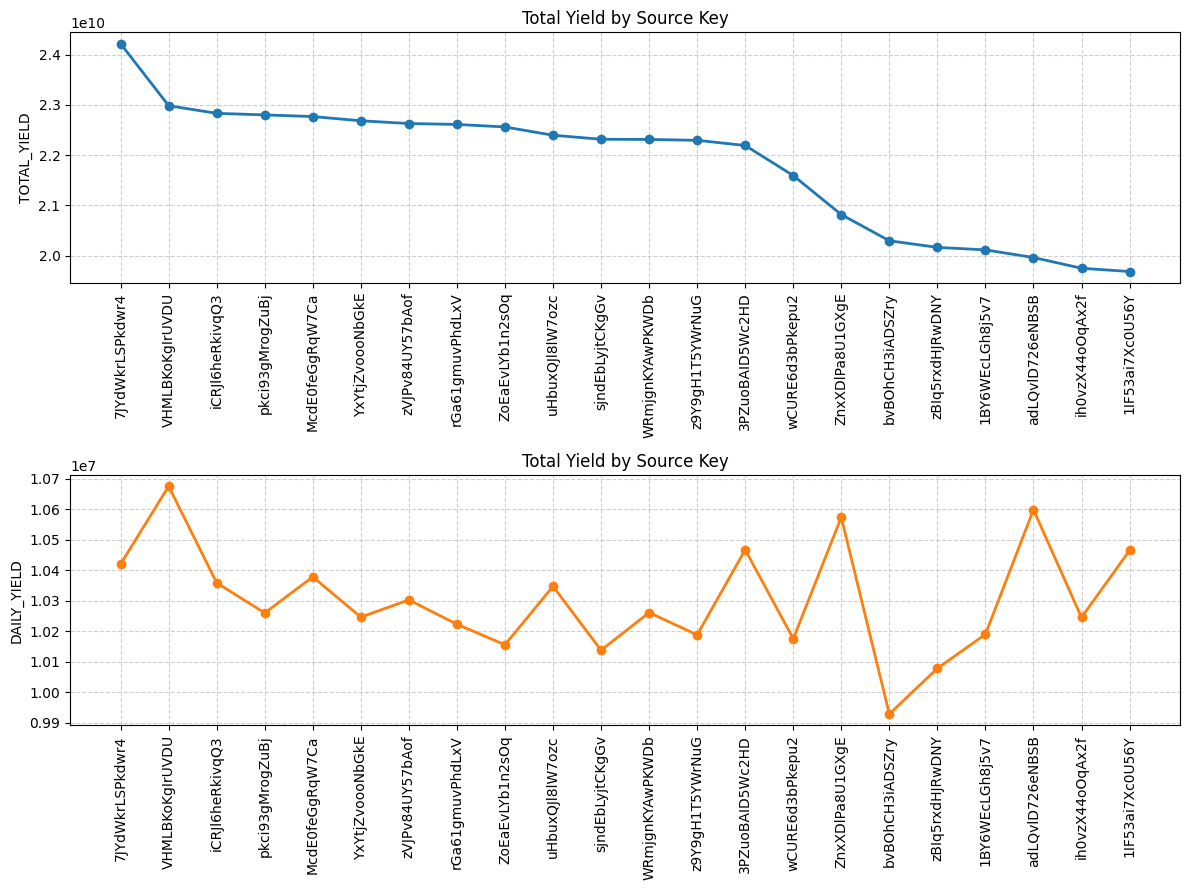

In [17]:
plt.figure(figsize=(12, 9))

plt.subplot(2, 1, 1)
plt.plot(max_yield['SOURCE_KEY_INV'], max_yield['TOTAL_YIELD'], color='tab:blue', marker='o', linewidth=2)
plt.title('Total Yield by Source Key')
plt.ylabel('TOTAL_YIELD')
plt.xticks(rotation=90)
plt.grid(True, linestyle='--', alpha=0.6)

plt.subplot(2, 1, 2)
plt.plot(max_yield['SOURCE_KEY_INV'], max_yield['DAILY_YIELD'], color='tab:orange', marker='o', linewidth=2)
plt.title('Total Yield by Source Key')
plt.ylabel('DAILY_YIELD')
plt.xticks(rotation=90)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## Insights (Approximate)

#### TOTAL YIELD
1. One inverter (7JYdWkrLSPkdwr4) has generated the highest cumulative energy.
2. 13 inverters are in the average band.
3. Two inverters (wCURE6d3bPkepu2, ZnxXDlPa8U1GXgE) are moderately below average.
4. Six inverters have generated the lowest cumulative energy.

#### DAILY YIELD
1. bvBOhCH3iADSZry is the lowest and needs investigation.
2. VHMLBKoKgIrUVDU, adLQvlD726eNBSB and ZnxXDlPa8U1GXgE are the top performers.
3. zBlq5rxdHJRwDNY is below average.
4. The rest are near the average, within about ±1.5%.

In [18]:
print(plt.colormaps())

['magma', 'inferno', 'plasma', 'viridis', 'cividis', 'twilight', 'twilight_shifted', 'turbo', 'berlin', 'managua', 'vanimo', 'Blues', 'BrBG', 'BuGn', 'BuPu', 'CMRmap', 'GnBu', 'Greens', 'Greys', 'OrRd', 'Oranges', 'PRGn', 'PiYG', 'PuBu', 'PuBuGn', 'PuOr', 'PuRd', 'Purples', 'RdBu', 'RdGy', 'RdPu', 'RdYlBu', 'RdYlGn', 'Reds', 'Spectral', 'Wistia', 'YlGn', 'YlGnBu', 'YlOrBr', 'YlOrRd', 'afmhot', 'autumn', 'binary', 'bone', 'brg', 'bwr', 'cool', 'coolwarm', 'copper', 'cubehelix', 'flag', 'gist_earth', 'gist_gray', 'gist_heat', 'gist_ncar', 'gist_rainbow', 'gist_stern', 'gist_yarg', 'gnuplot', 'gnuplot2', 'gray', 'hot', 'hsv', 'jet', 'nipy_spectral', 'ocean', 'pink', 'prism', 'rainbow', 'seismic', 'spring', 'summer', 'terrain', 'winter', 'Accent', 'Dark2', 'Paired', 'Pastel1', 'Pastel2', 'Set1', 'Set2', 'Set3', 'tab10', 'tab20', 'tab20b', 'tab20c', 'grey', 'gist_grey', 'gist_yerg', 'Grays', 'magma_r', 'inferno_r', 'plasma_r', 'viridis_r', 'cividis_r', 'twilight_r', 'twilight_shifted_r', 't

## Can we predict the power generation for next couple of days? - this allows for better grid management.

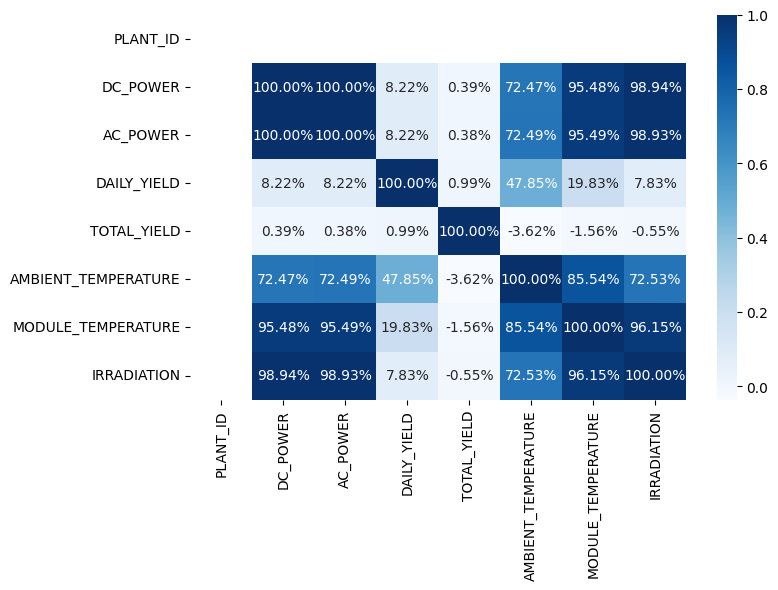

In [19]:
#Need to chcek on which factor 'DAILY_YIELD' is highly dependant or not
plt.figure(figsize=(8,5))
sns.heatmap(master.corr(numeric_only=True), cmap='Blues', annot=True, fmt='0.2%')
plt.show()

1. Some Basics of solar power generation.
2. Basically it depend on sunlight, Irradiance. But from above it is seen that its only 7.82% corelated. and 47.85% with Ambient Temp.
3. When seen all data, irradiance is 0.0 in night time, and while making heatmap, it takes all reading during night time also.
4. So need to seperate night time reading from main data.
5. But if we just skip night time data, model will get confused cz after every certain time, there will be no any data till next day morning.
6. So to avoid this, lets make daily generation, by grouping Date and Inverters.
7. Doing this seperately on P1_gen and P1_sen 

In [20]:
daily_gen = P1_gen.copy()
daily_gen['DATE_TIME'] = pd.to_datetime(daily_gen['DATE_TIME']).dt.date
daily_gen = daily_gen.groupby(['DATE_TIME', 'SOURCE_KEY']).agg({
    'DC_POWER': 'max',
    'AC_POWER': 'max',
    'DAILY_YIELD': 'max'
}).reset_index()
daily_gen

,DATE_TIME,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD
0,2020-05-15,1BY6WEcLGh8j5v7,10642.75000,1039.350000,5754.0
1,2020-05-15,1IF53ai7Xc0U56Y,12194.71429,1189.642857,6357.0
2,2020-05-15,3PZuoBAID5Wc2HD,12158.28571,1185.957143,6274.0
3,2020-05-15,7JYdWkrLSPkdwr4,11674.75000,1139.525000,6116.0
4,2020-05-15,McdE0feGgRqW7Ca,12040.57143,1174.300000,6471.0
...,...,...,...,...,...
743,2020-06-17,uHbuxQJl8lW7ozc,13627.42857,1328.657143,5967.0
744,2020-06-17,wCURE6d3bPkepu2,13692.85714,1335.085714,5883.0
745,2020-06-17,z9Y9gH1T5YWrNuG,13287.85714,1295.557143,5819.0
746,2020-06-17,zBIq5rxdHJRwDNY,13586.50000,1324.675000,5817.0


In [21]:
daily_sens = P1_sen.copy()
daily_sens['DATE_TIME'] = pd.to_datetime(daily_sens['DATE_TIME']).dt.date
daily_sens = daily_sens[daily_sens['IRRADIATION'] > 0]

daily_sens = daily_sens.groupby('DATE_TIME').agg({
    'AMBIENT_TEMPERATURE': 'mean',
    'MODULE_TEMPERATURE': 'mean',
    'IRRADIATION': 'mean'
}).reset_index()

daily_sens

,DATE_TIME,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15,29.820316,39.924700,0.352537
1,2020-05-16,28.564478,38.616842,0.358686
2,2020-05-17,29.494486,42.028687,0.440988
3,2020-05-18,25.144056,33.573602,0.293586
4,2020-05-19,27.403739,37.733532,0.368262
5,2020-05-20,27.053268,39.338876,0.493123
6,2020-05-21,29.383561,45.335427,0.535368
7,2020-05-22,28.488995,40.469186,0.417342
8,2020-05-23,29.362050,45.278784,0.532789
9,2020-05-24,29.775916,42.970463,0.470513


In [22]:
daily_gen.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 748 entries, 0 to 747
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   DATE_TIME    748 non-null    object 
 1   SOURCE_KEY   748 non-null    object 
 2   DC_POWER     748 non-null    float64
 3   AC_POWER     748 non-null    float64
 4   DAILY_YIELD  748 non-null    float64
dtypes: float64(3), object(2)
memory usage: 29.3+ KB


In [23]:
daily_sens.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34 entries, 0 to 33
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   DATE_TIME            34 non-null     object 
 1   AMBIENT_TEMPERATURE  34 non-null     float64
 2   MODULE_TEMPERATURE   34 non-null     float64
 3   IRRADIATION          34 non-null     float64
dtypes: float64(3), object(1)
memory usage: 1.2+ KB


In [24]:
#Merging daily data in one master_daily
master_daily = pd.merge(daily_gen, daily_sens, on = 'DATE_TIME', how='left') 
master_daily

,DATE_TIME,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15,1BY6WEcLGh8j5v7,10642.75000,1039.350000,5754.0,29.820316,39.924700,0.352537
1,2020-05-15,1IF53ai7Xc0U56Y,12194.71429,1189.642857,6357.0,29.820316,39.924700,0.352537
2,2020-05-15,3PZuoBAID5Wc2HD,12158.28571,1185.957143,6274.0,29.820316,39.924700,0.352537
3,2020-05-15,7JYdWkrLSPkdwr4,11674.75000,1139.525000,6116.0,29.820316,39.924700,0.352537
4,2020-05-15,McdE0feGgRqW7Ca,12040.57143,1174.300000,6471.0,29.820316,39.924700,0.352537
...,...,...,...,...,...,...,...,...
743,2020-06-17,uHbuxQJl8lW7ozc,13627.42857,1328.657143,5967.0,25.551221,34.163934,0.326702
744,2020-06-17,wCURE6d3bPkepu2,13692.85714,1335.085714,5883.0,25.551221,34.163934,0.326702
745,2020-06-17,z9Y9gH1T5YWrNuG,13287.85714,1295.557143,5819.0,25.551221,34.163934,0.326702
746,2020-06-17,zBIq5rxdHJRwDNY,13586.50000,1324.675000,5817.0,25.551221,34.163934,0.326702


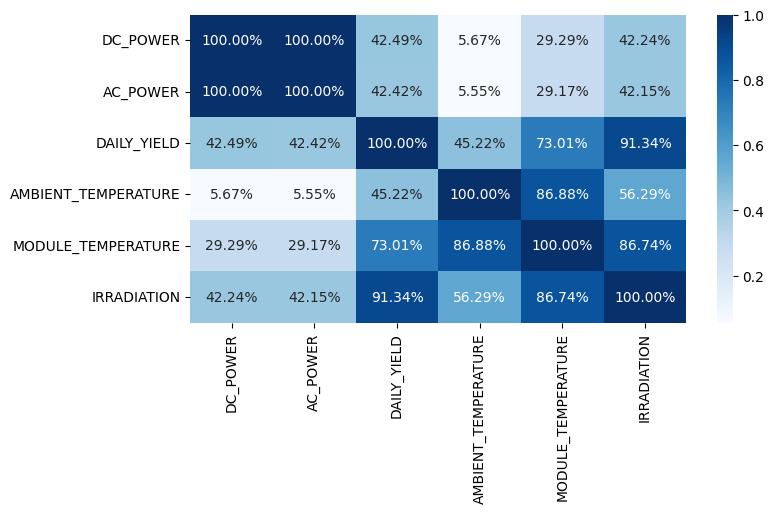

In [25]:
#Now checking correlation
plt.figure(figsize=(8,4))
sns.heatmap(master_daily.corr(numeric_only=True), cmap='Blues', annot=True, fmt='0.2%')
plt.show()

## Prediction model using Linear Regression
1. Here now clearly seen that DAILY_YIELD is highly correlated to IRRADIATION (91.34%)
2. We can make Linear Regression model to predict the power generation for next couple of days.

In [26]:
#Importing libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

In [27]:
master_daily.columns

Index(['DATE_TIME', 'SOURCE_KEY', 'DC_POWER', 'AC_POWER', 'DAILY_YIELD',
       'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION'],
      dtype='object')

In [28]:
#making datasets
X = master_daily.drop(columns=['DATE_TIME', 'SOURCE_KEY', 'DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'MODULE_TEMPERATURE'])
y = master_daily['DAILY_YIELD']

In [29]:
#making train and test sets, checking size/shape
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=10)
print ('shape of X_train:', X_train.shape)
print ('shape of y_train:', y_train.shape)
print ('shape of X_test:', X_test.shape)
print ('shape of y_test:', y_test.shape)

shape of X_train: (598, 2)
shape of y_train: (598,)
shape of X_test: (150, 2)
shape of y_test: (150,)


In [30]:
#making linear regression model
solar_model = LinearRegression()
solar_model

LinearRegression()

In [31]:
#training model
solar_model.fit(X_train, y_train)

LinearRegression()

In [32]:
#Predict from X_test and checking size/shape
y_pred = solar_model.predict(X_test)
y_pred.shape

(150,)

In [33]:
#Checking performance on X_test and error
r2score = r2_score(y_test, y_pred)
rmse= np.sqrt(mean_squared_error(y_test, y_pred))
error = (rmse/y.mean())*100

print('R² Score :', round(r2score*100,2),'%',sep='')
print ('Rot Mean Squared Error is :', round(rmse,2))
print ('Relative Error Magnitude :', round(error,2),'%',sep='')

R² Score :86.99%
Rot Mean Squared Error is : 345.17
Relative Error Magnitude :4.8%


## Prediction model using Decision Tree

In [34]:
# Importing libraries
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor

In [35]:
# Models already made...(Trainning and testing model)
# So making DecisionTree and trinned the data
DT_Model = DecisionTreeRegressor(random_state=10)
DT_Model.fit(X_train, y_train)

DecisionTreeRegressor(random_state=10)

In [36]:
# Predict the data
yDT_pred = DT_Model.predict(X_test)
print (X_test.shape)
print(yDT_pred.shape)

(150, 2)
(150,)


In [37]:
#Checking model performance
r2DT = (r2_score(y_test, yDT_pred))*100
rmseDT = np.sqrt(mean_squared_error(y_test, yDT_pred))
errorDT = (rmseDT/y_train.mean())*100

print('DT-R2 score is : ', round(r2DT,2),'%',sep='')
print ('DT Root Mean Sqaured error is :', round(rmseDT,2))
print ('DT-relative error magnitude is :', round(errorDT,2),'%', sep='')

DT-R2 score is : 93.93%
DT Root Mean Sqaured error is : 235.79
DT-relative error magnitude is :3.28%


## Prediction model using Random Forest

In [38]:
## Models already made...(Trainning and testing model)
# So making DecisionTree and trinned the data
RF_model = RandomForestRegressor(random_state=10)
RF_model.fit(X_train, y_train)

# Predicting data
yRF_pred = RF_model.predict(X_test)

print(yRF_pred.shape)
print(X_test.shape)
RF_model

(150,)
(150, 2)


RandomForestRegressor(random_state=10)

In [39]:
# Checking model performance
RFr2 = round(r2_score(y_test, yRF_pred)*100,2)
RFrmse = np.sqrt(mean_squared_error(y_test, yRF_pred))
RFerror = (RFrmse/y_train.mean()*100)

print('RF-R2 score is :', RFr2,'%',sep='')
print('RF- Root Mean Squared value', round(RFrmse,2))
print('RF Relative Error magnitude :', round(RFerror,2),'%', sep='')

RF-R2 score is :93.86%
RF- Root Mean Squared value 237.18
RF Relative Error magnitude :3.3%


## Can we predict the power generation for next couple of days? - this allows for better grid management.
### ANSWER-
- As of now, we cant predict any power generation, as we dnt have any future weather forcast(IRRADIATION) values. Bt at this point what can say, our model is ready, it can give / predict future power generation with relative error of "4.8%" Our model is working on "86.99%"
- 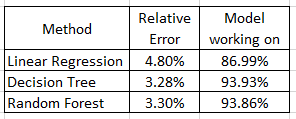

## Can we identify the need for panel cleaning/maintenance?

1. For identifying Panel cleaning or Maintenance we calculate plant average generation for each day, then compare that average generation with each inverter, If we observed any value drops more than 10% then we can assume that cleaning or maintenance is needed at that point/ inverter

In [40]:
master_daily.sample(2)

,DATE_TIME,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
342,2020-05-30,iCRJl6heRkivqQ3,14224.85714,1386.942857,7345.0,26.766419,38.802237,0.420674
216,2020-05-24,wCURE6d3bPkepu2,12885.28571,1256.300000,7961.0,29.775916,42.970463,0.470513


In [41]:
# creating new table
cleaning = master_daily[['DATE_TIME', 'SOURCE_KEY', 'DAILY_YIELD']].copy()

In [42]:
#Adding new column with average daily generation
cleaning['DAILY_AVG_YIELD'] = cleaning.groupby('DATE_TIME')['DAILY_YIELD'].transform('mean')
cleaning

,DATE_TIME,SOURCE_KEY,DAILY_YIELD,DAILY_AVG_YIELD
0,2020-05-15,1BY6WEcLGh8j5v7,5754.0,6248.772727
1,2020-05-15,1IF53ai7Xc0U56Y,6357.0,6248.772727
2,2020-05-15,3PZuoBAID5Wc2HD,6274.0,6248.772727
3,2020-05-15,7JYdWkrLSPkdwr4,6116.0,6248.772727
4,2020-05-15,McdE0feGgRqW7Ca,6471.0,6248.772727
...,...,...,...,...
743,2020-06-17,uHbuxQJl8lW7ozc,5967.0,5889.590909
744,2020-06-17,wCURE6d3bPkepu2,5883.0,5889.590909
745,2020-06-17,z9Y9gH1T5YWrNuG,5819.0,5889.590909
746,2020-06-17,zBIq5rxdHJRwDNY,5817.0,5889.590909


In [43]:
#Showing difference
cleaning['DIFFERENCE'] = cleaning['DAILY_AVG_YIELD']-cleaning['DAILY_YIELD']

In [44]:
#sorting inverters which having more than 10% drop
cleaning['ACTION_NEED'] = cleaning['DAILY_YIELD']<(0.9*cleaning['DAILY_AVG_YIELD'])

In [45]:
#Labeling YES and NO, YES means Action need either Maintenance or cleaning need, NO- No any action need
cleaning['ACTION_NEED'] = cleaning['ACTION_NEED'].map({True : 'YES', False :'NO'})
cleaning

,DATE_TIME,SOURCE_KEY,DAILY_YIELD,DAILY_AVG_YIELD,DIFFERENCE,ACTION_NEED
0,2020-05-15,1BY6WEcLGh8j5v7,5754.0,6248.772727,494.772727,NO
1,2020-05-15,1IF53ai7Xc0U56Y,6357.0,6248.772727,-108.227273,NO
2,2020-05-15,3PZuoBAID5Wc2HD,6274.0,6248.772727,-25.227273,NO
3,2020-05-15,7JYdWkrLSPkdwr4,6116.0,6248.772727,132.772727,NO
4,2020-05-15,McdE0feGgRqW7Ca,6471.0,6248.772727,-222.227273,NO
...,...,...,...,...,...,...
743,2020-06-17,uHbuxQJl8lW7ozc,5967.0,5889.590909,-77.409091,NO
744,2020-06-17,wCURE6d3bPkepu2,5883.0,5889.590909,6.590909,NO
745,2020-06-17,z9Y9gH1T5YWrNuG,5819.0,5889.590909,70.590909,NO
746,2020-06-17,zBIq5rxdHJRwDNY,5817.0,5889.590909,72.590909,NO


In [46]:
# Count how many times each inverter needed action
action_counts = cleaning[cleaning['ACTION_NEED'] == 'YES']['SOURCE_KEY'].value_counts()
action_counts

SOURCE_KEY
1BY6WEcLGh8j5v7    2
bvBOhCH3iADSZry    2
wCURE6d3bPkepu2    1
z9Y9gH1T5YWrNuG    1
Name: count, dtype: int64

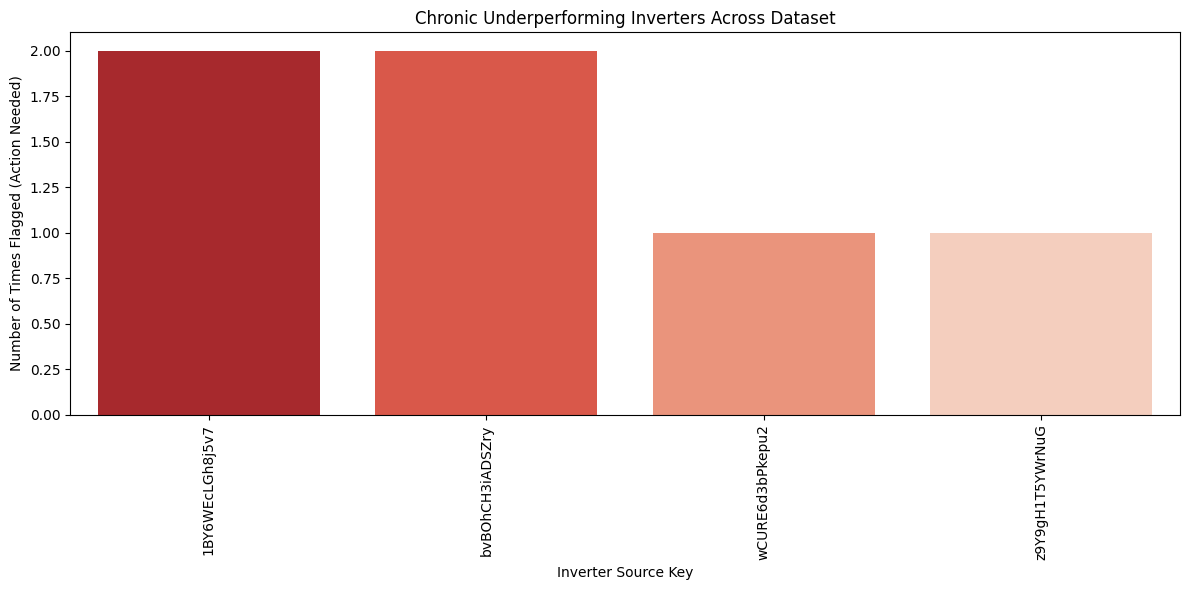

In [47]:
#Graphical representation (Chronic Underperforming Inverters Across Dataset)
plt.figure(figsize=(12, 6))
sns.barplot(x=action_counts.index, y=action_counts.values, palette='Reds_r')
plt.xticks(rotation=90)
plt.xlabel('Inverter Source Key')
plt.ylabel('Number of Times Flagged (Action Needed)')
plt.title('Chronic Underperforming Inverters Across Dataset')
plt.tight_layout()
plt.show()

In [48]:
cleaning['LOWER_THRESHOLD'] = cleaning['DAILY_AVG_YIELD'] * 0.9
cleaning

,DATE_TIME,SOURCE_KEY,DAILY_YIELD,DAILY_AVG_YIELD,DIFFERENCE,ACTION_NEED,LOWER_THRESHOLD
0,2020-05-15,1BY6WEcLGh8j5v7,5754.0,6248.772727,494.772727,NO,5623.895455
1,2020-05-15,1IF53ai7Xc0U56Y,6357.0,6248.772727,-108.227273,NO,5623.895455
2,2020-05-15,3PZuoBAID5Wc2HD,6274.0,6248.772727,-25.227273,NO,5623.895455
3,2020-05-15,7JYdWkrLSPkdwr4,6116.0,6248.772727,132.772727,NO,5623.895455
4,2020-05-15,McdE0feGgRqW7Ca,6471.0,6248.772727,-222.227273,NO,5623.895455
...,...,...,...,...,...,...,...
743,2020-06-17,uHbuxQJl8lW7ozc,5967.0,5889.590909,-77.409091,NO,5300.631818
744,2020-06-17,wCURE6d3bPkepu2,5883.0,5889.590909,6.590909,NO,5300.631818
745,2020-06-17,z9Y9gH1T5YWrNuG,5819.0,5889.590909,70.590909,NO,5300.631818
746,2020-06-17,zBIq5rxdHJRwDNY,5817.0,5889.590909,72.590909,NO,5300.631818


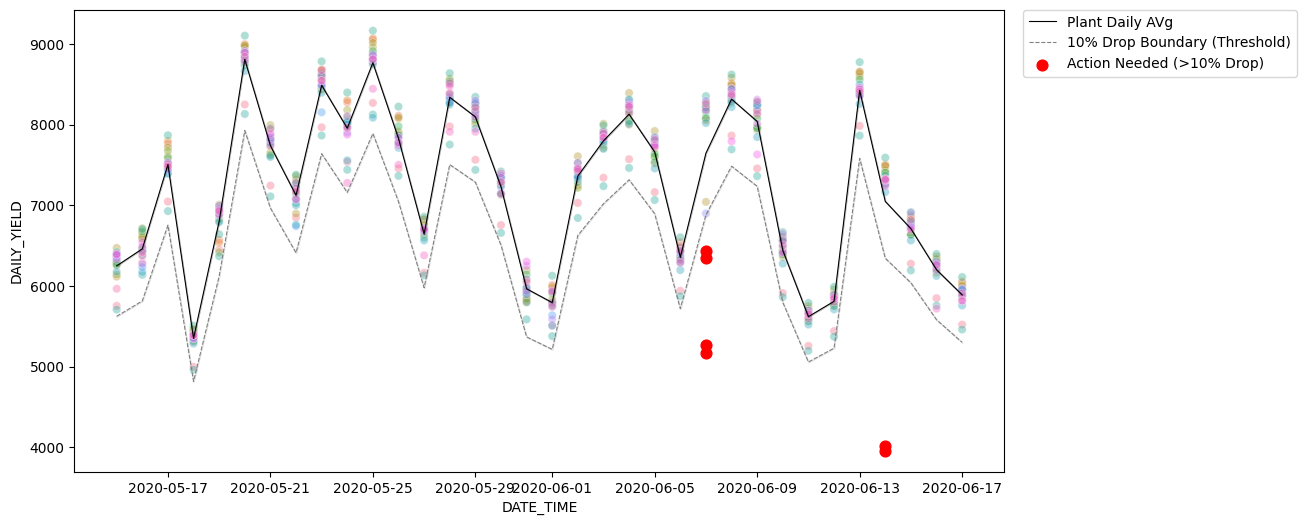

In [49]:
#Scatterplot representation
plt.figure(figsize=(12,6))
sns.scatterplot(data=cleaning, x='DATE_TIME', y='DAILY_YIELD', hue='SOURCE_KEY', alpha=0.4, legend=False)
sns.lineplot(data=cleaning, x='DATE_TIME', y='DAILY_AVG_YIELD', color = 'black', linewidth=0.8, label='Plant Daily AVg')
sns.lineplot(data=cleaning, x='DATE_TIME', y='LOWER_THRESHOLD', color='grey', linewidth=0.8, linestyle = '--', label='10% Drop Boundary (Threshold)')
flagged = cleaning[cleaning['ACTION_NEED'] == 'YES']
plt.scatter(flagged['DATE_TIME'],flagged['DAILY_YIELD'], color='red', s=60, zorder=5, label='Action Needed (>10% Drop)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)
plt.show()

## Cleaning or Maintenance
- As seen from above it is clearly seen that 4 inverters with SOURCE_KEY '1BY6WEcLGh8j5v7', 'bvBOhCH3iADSZry', 'wCURE6d3bPkepu2', 'z9Y9gH1T5YWrNuG' are generating less than 10% power with respect to others.
- So either cleaning modules connected to these inverter is necessary or maintenance is necessary. 

## Can we identify faulty or suboptimally performing equipment?
1. Faulty equipments means inverter is generating zero power in day time
2. For suboptimally performing equipment we can use above analysis as output of that analysis gives us SOURCE_KEY name of inverter who are performing less 10% of average of others
3. For finding Faulty equipment we need master data set, with 15 min time interval.
4. we can filter out inverter /SOURCE_KEY name by logic like DC_POWER or AC_POWER is zero in day time when IRRADIATION is greater than 0.2

In [50]:
#making new data with IRRADIATION greater than 0.2
faulty_equim = master[(master['IRRADIATION'] > 0.2) & (master['DC_POWER']==0.0)]
order_inv=faulty_equim['SOURCE_KEY_INV'].value_counts().index


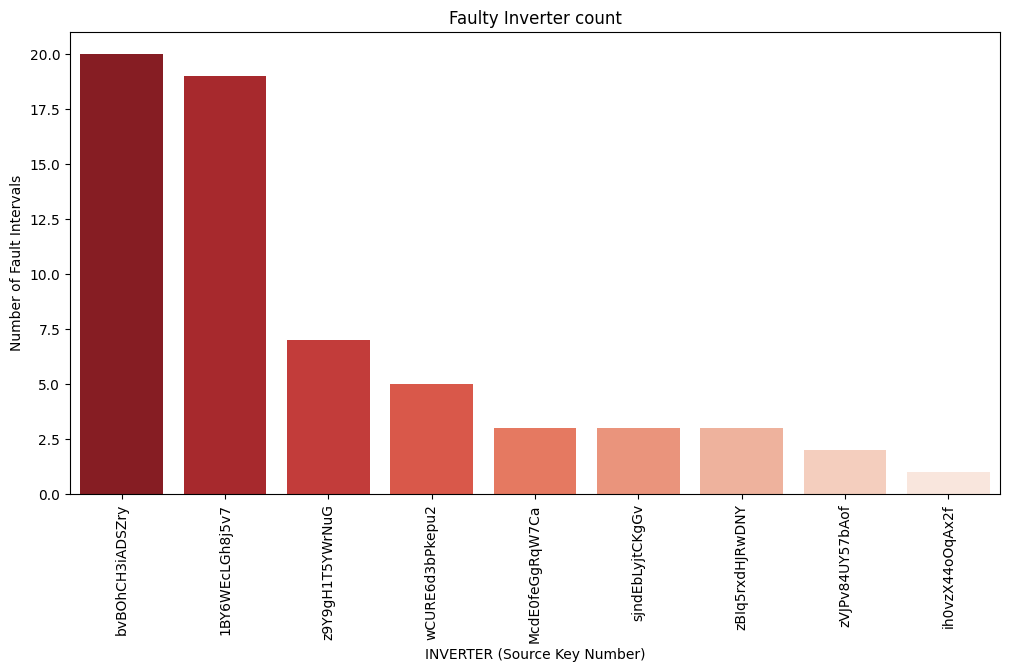

In [51]:
#Fault Frequency Bar Chart (Who fails the most?)

plt.figure(figsize=(12,6))
sns.countplot(data=faulty_equim, x='SOURCE_KEY_INV', palette='Reds_r',order=order_inv )
plt.xlabel('INVERTER (Source Key Number)')
plt.ylabel('Number of Fault Intervals')
plt.title('Faulty Inverter count')
plt.xticks(rotation=90)
plt.show()

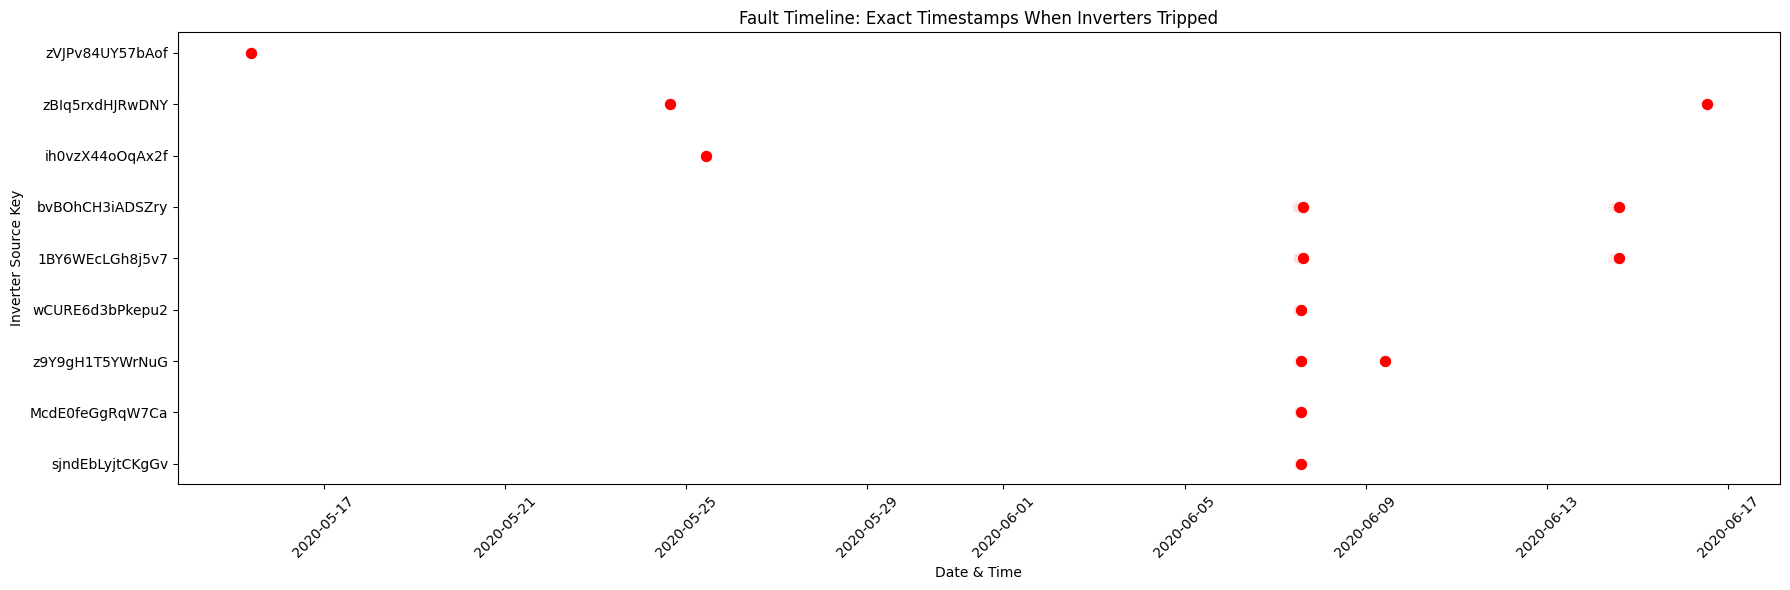

In [52]:
#
plt.figure(figsize=(18,6))
sns.scatterplot(data=faulty_equim, y='SOURCE_KEY_INV', x='DATE_TIME', color='red',markers='x', s=80)
plt.xlabel('Date & Time')
plt.ylabel('Inverter Source Key')
plt.title('Fault Timeline: Exact Timestamps When Inverters Tripped')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [53]:
order_inv
faulty_equim['SOURCE_KEY_INV'].value_counts()

SOURCE_KEY_INV
bvBOhCH3iADSZry    20
1BY6WEcLGh8j5v7    19
z9Y9gH1T5YWrNuG     7
wCURE6d3bPkepu2     5
McdE0feGgRqW7Ca     3
sjndEbLyjtCKgGv     3
zBIq5rxdHJRwDNY     3
zVJPv84UY57bAof     2
ih0vzX44oOqAx2f     1
Name: count, dtype: int64

## Faulty or suboptimally performing equipment.
- For suboptimally performing equipment,  below 4 inverters are generating less than 10% power with respect to others.
    - 1BY6WEcLGh8j5v7
    - bvBOhCH3iADSZry
    - wCURE6d3bPkepu2
    - z9Y9gH1T5YWrNuG
-  Faulty equipment from above graphs we can clearly seen that
    -  1BY6WEcLGh8j5v7 and bvBOhCH3iADSZry these two inverters fails maximum time    (20 and 19 times respectively)
    -  And z9Y9gH1T5YWrNuG this inverter comes in 3rd position with respect to failure count.
    -  These all three inverters are also seen in above (under suboptimally performing equipment)